# DeepLense Specific Test VI: EDSR super-resolution, then transfer to real telescope images

**Model.** An EDSR-style network (Lim et al., 2017, "Enhanced Deep Residual Networks for Single Image Super-Resolution"):
16 residual blocks with 64 channels, no batch norm, working at the low resolution, then a sub-pixel (PixelShuffle) 2× upsampler.
The network's output is **added to the bicubic upsampling** of the input, and its last layer starts at zero. So before training
it gives exactly the bicubic baseline of notebook 04, and training only has to learn the missing detail.

**Plan.**
1. **VI.A:** train on the 8,100 simulated train pairs with L1 loss; choose the epoch, and whether to use 8-view test-time
   augmentation, on the 900 validation pairs; report MSE / PSNR / SSIM on the 1,000 test pairs.
2. **VI.B:** compare on the 300 real pairs (243 train / 27 valid / 30 test):
   the VI.A model **without** fine-tuning, the VI.A model **fine-tuned**, and the same network **trained from scratch** on VI.B only.
   Baselines from notebook 04 are included.

Data, split, metrics, model and training loop are in `src/deeplense_sr.py`. The split was fixed and saved in notebook 04.

`SMOKE=1` (environment variable) runs a tiny CPU check of every cell: few images, 1–2 epochs, the **validation set in place of
the test set**, and all outputs written to `runs/smoke/`. The real run uses the settings below, on the GPU if it is visible,
otherwise on 16 CPU threads. (The submitted run used the CPU, because the shared GPU was busy with another job.)

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path("~/gsoc/eval-tests/ml4sci-deeplense").expanduser()
sys.path.insert(0, str(ROOT / "src"))
import deeplense_sr as S

SMOKE = os.environ.get("SMOKE") == "1"
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = torch.backends.cudnn.allow_tf32 = True   # fp32 weights, TF32 maths on the GPU
device = torch.device("cuda" if torch.cuda.is_available() and not SMOKE else "cpu")
if device.type == "cpu":
    torch.set_num_threads(16)
if SMOKE:
    FIG = WEIGHTS = RUNS = REPORT = ROOT / "runs/smoke"
    REPORT.mkdir(parents=True, exist_ok=True)
else:
    FIG, WEIGHTS, RUNS, REPORT = ROOT / "report/figures", ROOT / "weights", ROOT / "runs", ROOT / "report"
print("device:", torch.cuda.get_device_name(0) if device.type == "cuda" else f"cpu ({torch.get_num_threads()} threads)", "| smoke test" if SMOKE else "| full run")

data = {w: S.load_pairs(w)[:2] for w in ["a", "b"]}
split = {w: S.load_split(w) for w in ["a", "b"]}
if SMOKE:   # tiny subsets, and never touch the test images
    for w, n in [("a", 128), ("b", 32)]:
        sp = split[w]
        split[w] = dict(train=sp["train"][:n], valid=sp["valid"][:16], test=sp["valid"][:16])
for w in ["a", "b"]:
    print(f"VI.{w.upper()}: " + " | ".join(f"{k} {len(v)}" for k, v in split[w].items()))

device: cpu (16 threads) | full run


VI.A: train 8100 | valid 900 | test 1000
VI.B: train 243 | valid 27 | test 30


## 1. Model check: before training, the network must equal bicubic upsampling

In [2]:
model = S.EDSR(n_blocks=16, channels=64).to(device)
LR_A, HR_A = data["a"]
idx = split["a"]["valid"][:32]
diff = np.abs(S.predict_sr(model, LR_A, idx, device) - S.upsample_np(LR_A[idx])).max()
print(f"parameters {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M | max |untrained - bicubic| = {diff:.2e}")
assert diff < 1e-5

parameters 1.37 M | max |untrained - bicubic| = 0.00e+00


## 2. Train on VI.A
Adam (lr 2e-4, betas 0.9 / 0.99), 1 warm-up epoch then cosine decay, batch 32, 40 epochs, L1 loss, random flips and
90° rotations applied identically to each LR / HR pair (a lens has no preferred orientation). Validation PSNR is measured
after every epoch, and the best epoch is kept.

epoch   1 | train L1 0.00513 | valid PSNR 42.249 dB SSIM 0.9771 | 530s


epoch   2 | train L1 0.00489 | valid PSNR 42.356 dB SSIM 0.9777 | 541s


epoch   3 | train L1 0.00488 | valid PSNR 42.355 dB SSIM 0.9777 | 555s


epoch   4 | train L1 0.00488 | valid PSNR 42.361 dB SSIM 0.9778 | 562s


epoch   5 | train L1 0.00488 | valid PSNR 42.366 dB SSIM 0.9778 | 565s


epoch   6 | train L1 0.00488 | valid PSNR 42.366 dB SSIM 0.9778 | 569s


... (30 outputs left out)

epoch  37 | train L1 0.00487 | valid PSNR 42.385 dB SSIM 0.9778 | 1092s


epoch  38 | train L1 0.00487 | valid PSNR 42.385 dB SSIM 0.9778 | 1070s


epoch  39 | train L1 0.00487 | valid PSNR 42.385 dB SSIM 0.9778 | 1080s


epoch  40 | train L1 0.00487 | valid PSNR 42.385 dB SSIM 0.9778 | 1037s

training time 495.3 min | best valid PSNR 42.385 dB at epoch 38


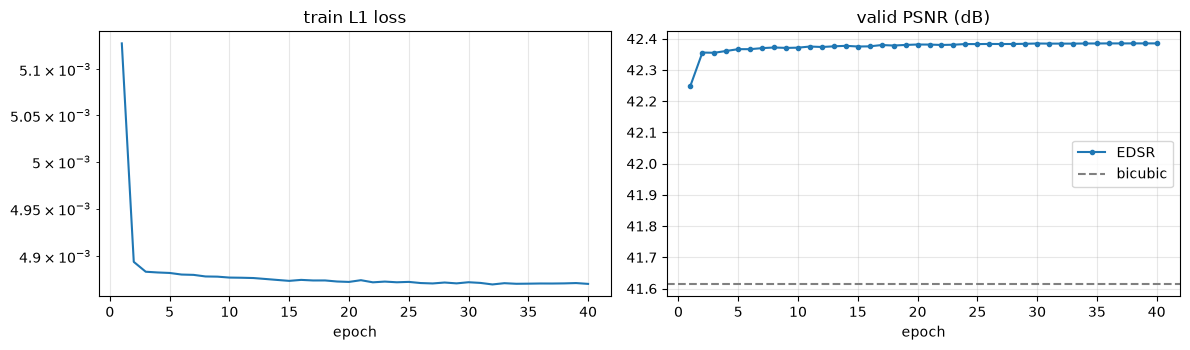

In [3]:
CFG_A = dict(epochs=40, batch_size=32, lr=2e-4, warmup_epochs=1, eval_every=1, seed=SEED)
if SMOKE: CFG_A.update(epochs=1, batch_size=16)
torch.manual_seed(SEED)
model = S.EDSR().to(device)
t0 = time.time()
hist_a, best_a = S.train_sr(model, LR_A, HR_A, split["a"]["train"], split["a"]["valid"], CFG_A, device)
print(f"\ntraining time {(time.time() - t0) / 60:.1f} min | best valid PSNR {best_a['psnr']:.3f} dB at epoch {best_a['epoch']}")
_ = model.load_state_dict(best_a["state"])
torch.save({"state_dict": best_a["state"], "cfg": CFG_A, "epoch": best_a["epoch"], "valid_psnr": best_a["psnr"]},
           WEIGHTS / "edsr_superres_a_best.pt")
hist_a.to_csv(RUNS / "edsr_superres_a_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(hist_a.epoch, hist_a.train_l1); axes[0].set_title("train L1 loss"); axes[0].set_yscale("log")
axes[1].plot(hist_a.epoch, hist_a.valid_psnr, marker="o", ms=3, label="EDSR")
bic_valid = S.metrics(S.upsample_np(LR_A[split["a"]["valid"]]), HR_A[split["a"]["valid"]]).psnr.mean()
axes[1].axhline(bic_valid, c="grey", ls="--", label="bicubic"); axes[1].set_title("valid PSNR (dB)"); axes[1].legend()
for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / "05_a_learning_curves.png", bbox_inches="tight"); plt.show()

## 3. VI.A: choose test-time augmentation on validation, then score the test set once

In [4]:
va, te = split["a"]["valid"], split["a"]["test"]
valid_rows = {"bicubic": S.metrics(S.upsample_np(LR_A[va]), HR_A[va]),
              "EDSR": S.metrics(S.predict_sr(model, LR_A, va, device), HR_A[va]),
              "EDSR + 8-view TTA": S.metrics(S.predict_sr(model, LR_A, va, device, tta=True), HR_A[va])}
display(pd.DataFrame({k: S.summarise(v) for k, v in valid_rows.items()}).T.round({"MSE": 7, "PSNR (dB)": 3, "SSIM": 4}))
USE_TTA = valid_rows["EDSR + 8-view TTA"].psnr.mean() > valid_rows["EDSR"].psnr.mean()
print("use TTA on test:", USE_TTA)

SR_A = S.predict_sr(model, LR_A, te, device, tta=USE_TTA)
BI_A = S.upsample_np(LR_A[te])
m_bic, m_edsr = S.metrics(BI_A, HR_A[te]), S.metrics(SR_A, HR_A[te])
test_a = pd.DataFrame({"bicubic": S.summarise(m_bic), "EDSR" + (" + TTA" if USE_TTA else ""): S.summarise(m_edsr)}).T
display(test_a.round({"MSE": 7, "PSNR (dB)": 3, "SSIM": 4}))
d, lo, hi, share = S.bootstrap_diff(m_edsr.psnr, m_bic.psnr)
print(f"PSNR gain over bicubic: {d:+.3f} dB, 95 % CI [{lo:+.3f}, {hi:+.3f}] (paired bootstrap over test images); "
      f"EDSR better on {(m_edsr.psnr > m_bic.psnr).mean():.1%} of test images")

,MSE,PSNR (dB),SSIM
bicubic,0.000070,41.613,0.9747
EDSR,0.000058,42.385,0.9778
EDSR + 8-view TTA,0.000058,42.386,0.9778


use TTA on test: True


,MSE,PSNR (dB),SSIM
bicubic,0.000069,41.624,0.9747
EDSR + TTA,0.000058,42.393,0.9778


PSNR gain over bicubic: +0.770 dB, 95 % CI [+0.764, +0.775] (paired bootstrap over test images); EDSR better on 100.0% of test images


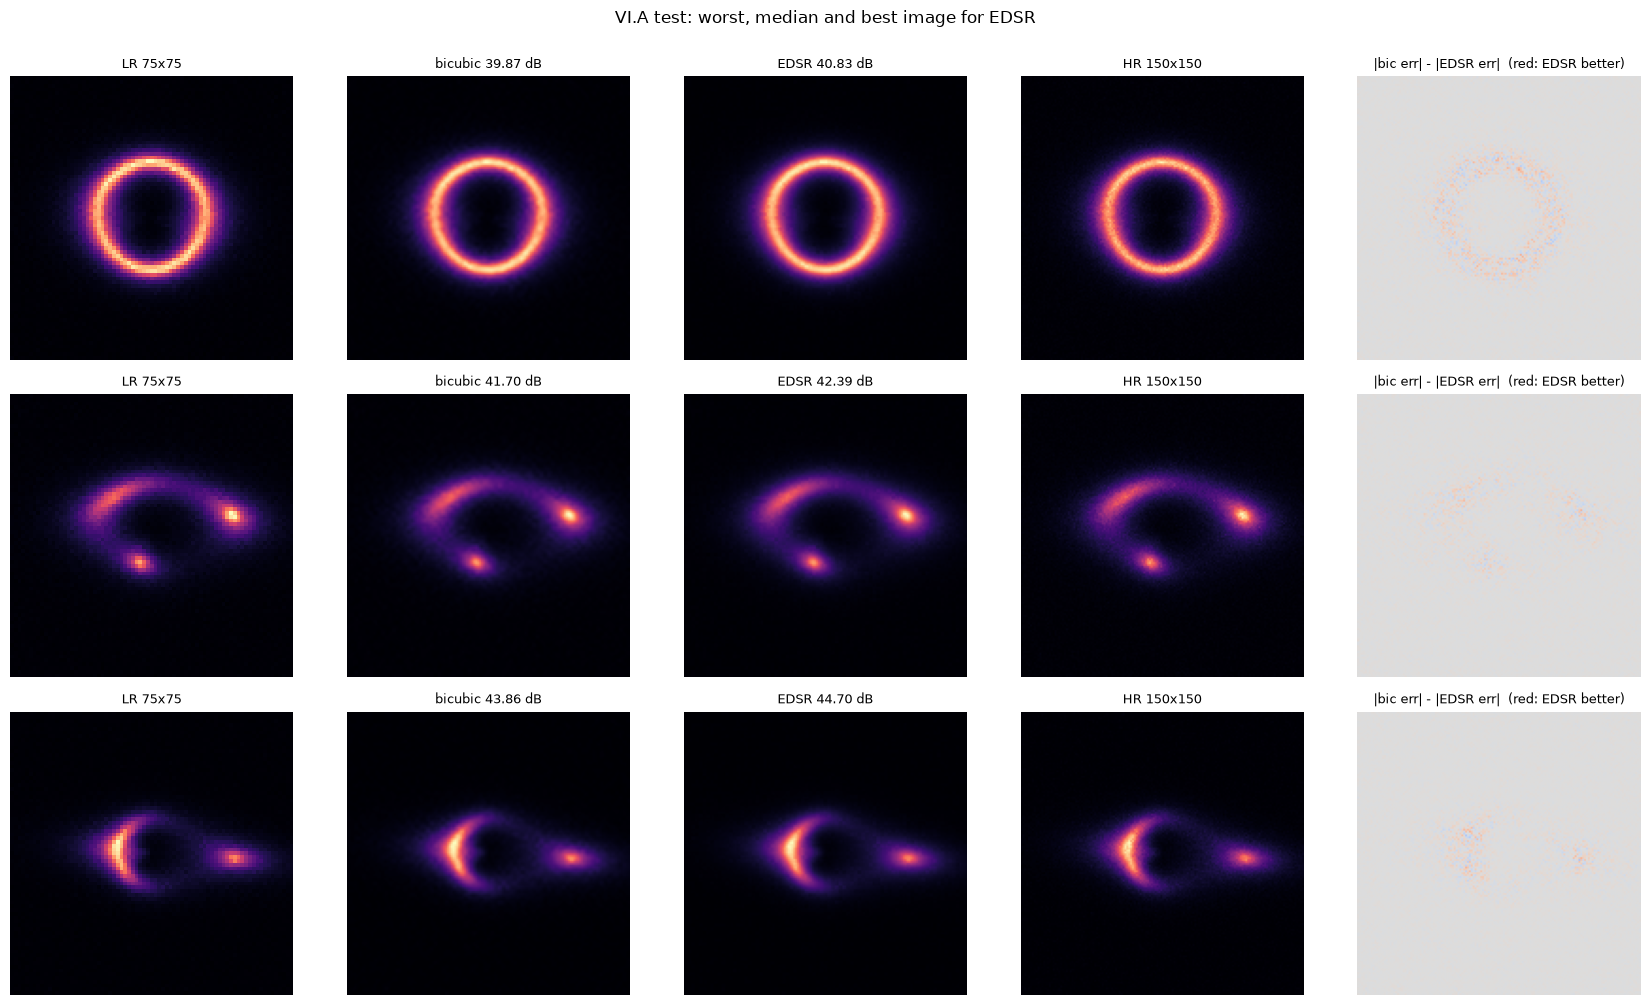

In [5]:
pick = te[np.argsort(m_edsr.psnr.values)[[0, len(te) // 2, -1]]]   # worst, median and best test image for EDSR
pos = {i: k for k, i in enumerate(te)}
fig, axes = plt.subplots(3, 5, figsize=(17, 10))
for r, i in enumerate(pick):
    k = pos[i]
    err_b, err_e = np.abs(BI_A[k] - HR_A[i]), np.abs(SR_A[k] - HR_A[i])
    vmax = max(err_b.max(), err_e.max())
    panels = [(LR_A[i], "LR 75x75", "magma", None), (BI_A[k], f"bicubic {m_bic.psnr[k]:.2f} dB", "magma", None),
              (SR_A[k], f"EDSR {m_edsr.psnr[k]:.2f} dB", "magma", None), (HR_A[i], "HR 150x150", "magma", None),
              (err_b - err_e, "|bic err| - |EDSR err|  (red: EDSR better)", "coolwarm", vmax)]
    for c, (img, title, cmap, v) in enumerate(panels):
        ax = axes[r, c]
        ax.imshow(img, cmap=cmap, origin="lower", **({"vmin": -v, "vmax": v} if v else {}))
        ax.set_title(title, fontsize=9); ax.axis("off")
fig.suptitle("VI.A test: worst, median and best image for EDSR", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "05_a_test_examples.png", bbox_inches="tight"); plt.show()

## 4. VI.B: transfer to real telescope pairs
Three ways to use the same network on the 243 VI.B train pairs, all chosen by validation PSNR on the 27 validation pairs:
* **no fine-tuning** — the VI.A model as it is;
* **fine-tuned** — start from the VI.A weights, train on VI.B (lr 1e-4);
* **from scratch** — same network and the same number of steps, but starting from the bicubic-equivalent initialisation
  (lr 2e-4), to show what the VI.A pre-training is worth.

The baselines are bicubic and bicubic + brightness fit from notebook 04.

**Brightness matching.** HSC (ground) and HST (space) images have very different background levels (notebook 04), and the
linear fit `HR ≈ a · bicubic(LR) + b` alone gains about 9 dB. That fit (a, b come from the **train** pairs only) is applied to the
LR input of every EDSR variant: `LR' = a · LR + b`. Bicubic weights sum to one, so bicubic(LR') = a · bicubic(LR) + b, and
every untrained network therefore starts exactly at the strongest baseline. Any further gain has to come from recovered detail.

--- fine-tuned


epoch  25 | train L1 0.01426 | valid PSNR 32.897 dB SSIM 0.8038 | 12s


epoch  50 | train L1 0.01423 | valid PSNR 33.103 dB SSIM 0.8040 | 11s


epoch  75 | train L1 0.01397 | valid PSNR 33.232 dB SSIM 0.8008 | 11s


epoch 100 | train L1 0.01373 | valid PSNR 33.364 dB SSIM 0.8125 | 9s


epoch 125 | train L1 0.01377 | valid PSNR 33.242 dB SSIM 0.8027 | 11s


... (7 outputs left out)

epoch 125 | train L1 0.01400 | valid PSNR 33.019 dB SSIM 0.8013 | 9s


epoch 150 | train L1 0.01374 | valid PSNR 33.216 dB SSIM 0.8082 | 10s


epoch 175 | train L1 0.01340 | valid PSNR 33.221 dB SSIM 0.8061 | 10s


epoch 200 | train L1 0.01342 | valid PSNR 33.172 dB SSIM 0.8063 | 10s
from scratch: 32.9 min | best valid PSNR 33.222 dB at epoch 185


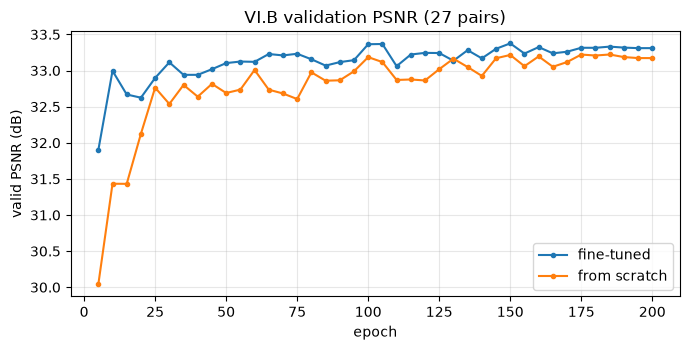

In [6]:
LR_B, HR_B = data["b"]
fit = json.loads((ROOT / "report/results_04_baselines.json").read_text())["vib_brightness_fit"]
LR_Bm = (fit["a"] * LR_B + fit["b"]).astype(np.float32)          # brightness-matched input for the networks
trb, vab, teb = split["b"]["train"], split["b"]["valid"], split["b"]["test"]
CFG_B = dict(epochs=200, batch_size=16, warmup_epochs=5, eval_every=5, seed=SEED)
if SMOKE: CFG_B.update(epochs=2, eval_every=1, warmup_epochs=1)

init_check = S.predict_sr(S.EDSR().to(device), LR_Bm, vab, device)
assert np.abs(init_check - (fit["a"] * S.upsample_np(LR_B[vab]) + fit["b"])).max() < 1e-5   # untrained = brightness-fit baseline

ck = torch.load(WEIGHTS / "edsr_superres_a_best.pt", map_location=device, weights_only=False)
models_b, hist_b = {}, {}
models_b["no fine-tuning"] = S.EDSR().to(device); models_b["no fine-tuning"].load_state_dict(ck["state_dict"])
for name, lr, init in [("fine-tuned", 1e-4, ck["state_dict"]), ("from scratch", 2e-4, None)]:
    torch.manual_seed(SEED)
    m = S.EDSR().to(device)
    if init is not None:
        m.load_state_dict(init)
    print(f"--- {name}")
    t0 = time.time()
    h, b = S.train_sr(m, LR_Bm, HR_B, trb, vab, dict(CFG_B, lr=lr), device,
                      log=lambda s: print(s) if (int(s.split()[1]) % 25 == 0 or SMOKE) else None)
    print(f"{name}: {(time.time() - t0) / 60:.1f} min | best valid PSNR {b['psnr']:.3f} dB at epoch {b['epoch']}")
    m.load_state_dict(b["state"]); models_b[name] = m; hist_b[name] = h
    torch.save({"state_dict": b["state"], "cfg": dict(CFG_B, lr=lr), "epoch": b["epoch"], "valid_psnr": b["psnr"]},
               WEIGHTS / f"edsr_superres_b_{name.replace(' ', '_').replace('-', '')}.pt")
    h.to_csv(RUNS / f"edsr_superres_b_{name.replace(' ', '_').replace('-', '')}_history.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.6))
for name, h in hist_b.items(): ax.plot(h.epoch, h.valid_psnr, marker="o", ms=3, label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("valid PSNR (dB)"); ax.set_title("VI.B validation PSNR (27 pairs)"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "05_b_learning_curves.png", bbox_inches="tight"); plt.show()

In [7]:
def methods_b(idx, tta):
    out = {"bicubic": S.upsample_np(LR_B[idx]),
           "bicubic + brightness fit": fit["a"] * S.upsample_np(LR_B[idx]) + fit["b"]}
    for name, m in models_b.items():
        out[f"EDSR, {name}"] = S.predict_sr(m, LR_Bm, idx, device, tta=tta)
    return out

# TTA choice on validation (for the fine-tuned model, the expected final model)
v_plain = S.metrics(S.predict_sr(models_b["fine-tuned"], LR_Bm, vab, device), HR_B[vab]).psnr.mean()
v_tta = S.metrics(S.predict_sr(models_b["fine-tuned"], LR_Bm, vab, device, tta=True), HR_B[vab]).psnr.mean()
USE_TTA_B = v_tta > v_plain
print(f"fine-tuned valid PSNR: plain {v_plain:.3f} dB, TTA {v_tta:.3f} dB -> use TTA: {USE_TTA_B}")

valid_b = {k: S.metrics(v, HR_B[vab]) for k, v in methods_b(vab, USE_TTA_B).items()}
sel_b = pd.DataFrame({k: S.summarise(v) for k, v in valid_b.items()}).T
display(sel_b.round({"MSE": 6, "PSNR (dB)": 2, "SSIM": 4}))
FINAL_B = sel_b["PSNR (dB)"].idxmax()
print("best on validation:", FINAL_B)

SR_B = methods_b(teb, USE_TTA_B)
test_b_img = {k: S.metrics(v, HR_B[teb]) for k, v in SR_B.items()}
test_b = pd.DataFrame({k: S.summarise(v) for k, v in test_b_img.items()}).T
display(test_b.round({"MSE": 6, "PSNR (dB)": 2, "SSIM": 4}))
comparisons = {}
for other in ["bicubic + brightness fit", "EDSR, from scratch", "EDSR, no fine-tuning"]:
    if other != FINAL_B:
        d, lo, hi, share = S.bootstrap_diff(test_b_img[FINAL_B].psnr, test_b_img[other].psnr)
        comparisons[other] = dict(diff=d, ci_low=lo, ci_high=hi, share_positive=share)
        print(f"{FINAL_B} minus {other}: {d:+.2f} dB PSNR, 95 % CI [{lo:+.2f}, {hi:+.2f}] ({len(teb)} test pairs, paired bootstrap)")

fine-tuned valid PSNR: plain 33.376 dB, TTA 33.307 dB -> use TTA: False


,MSE,PSNR (dB),SSIM
bicubic,0.009765,23.17,0.4152
bicubic + brightness fit,0.001504,30.45,0.6635
"EDSR, no fine-tuning",0.001472,30.53,0.6792
"EDSR, fine-tuned",0.001000,33.38,0.8110
"EDSR, from scratch",0.001026,33.22,0.8074


best on validation: EDSR, fine-tuned


,MSE,PSNR (dB),SSIM
bicubic,0.017874,20.25,0.3058
bicubic + brightness fit,0.002473,29.11,0.6704
"EDSR, no fine-tuning",0.002414,29.24,0.6915
"EDSR, fine-tuned",0.002127,32.41,0.7998
"EDSR, from scratch",0.002001,32.35,0.7975


EDSR, fine-tuned minus bicubic + brightness fit: +3.30 dB PSNR, 95 % CI [+2.17, +4.42] (30 test pairs, paired bootstrap)
EDSR, fine-tuned minus EDSR, from scratch: +0.06 dB PSNR, 95 % CI [-0.06, +0.17] (30 test pairs, paired bootstrap)
EDSR, fine-tuned minus EDSR, no fine-tuning: +3.16 dB PSNR, 95 % CI [+2.04, +4.26] (30 test pairs, paired bootstrap)


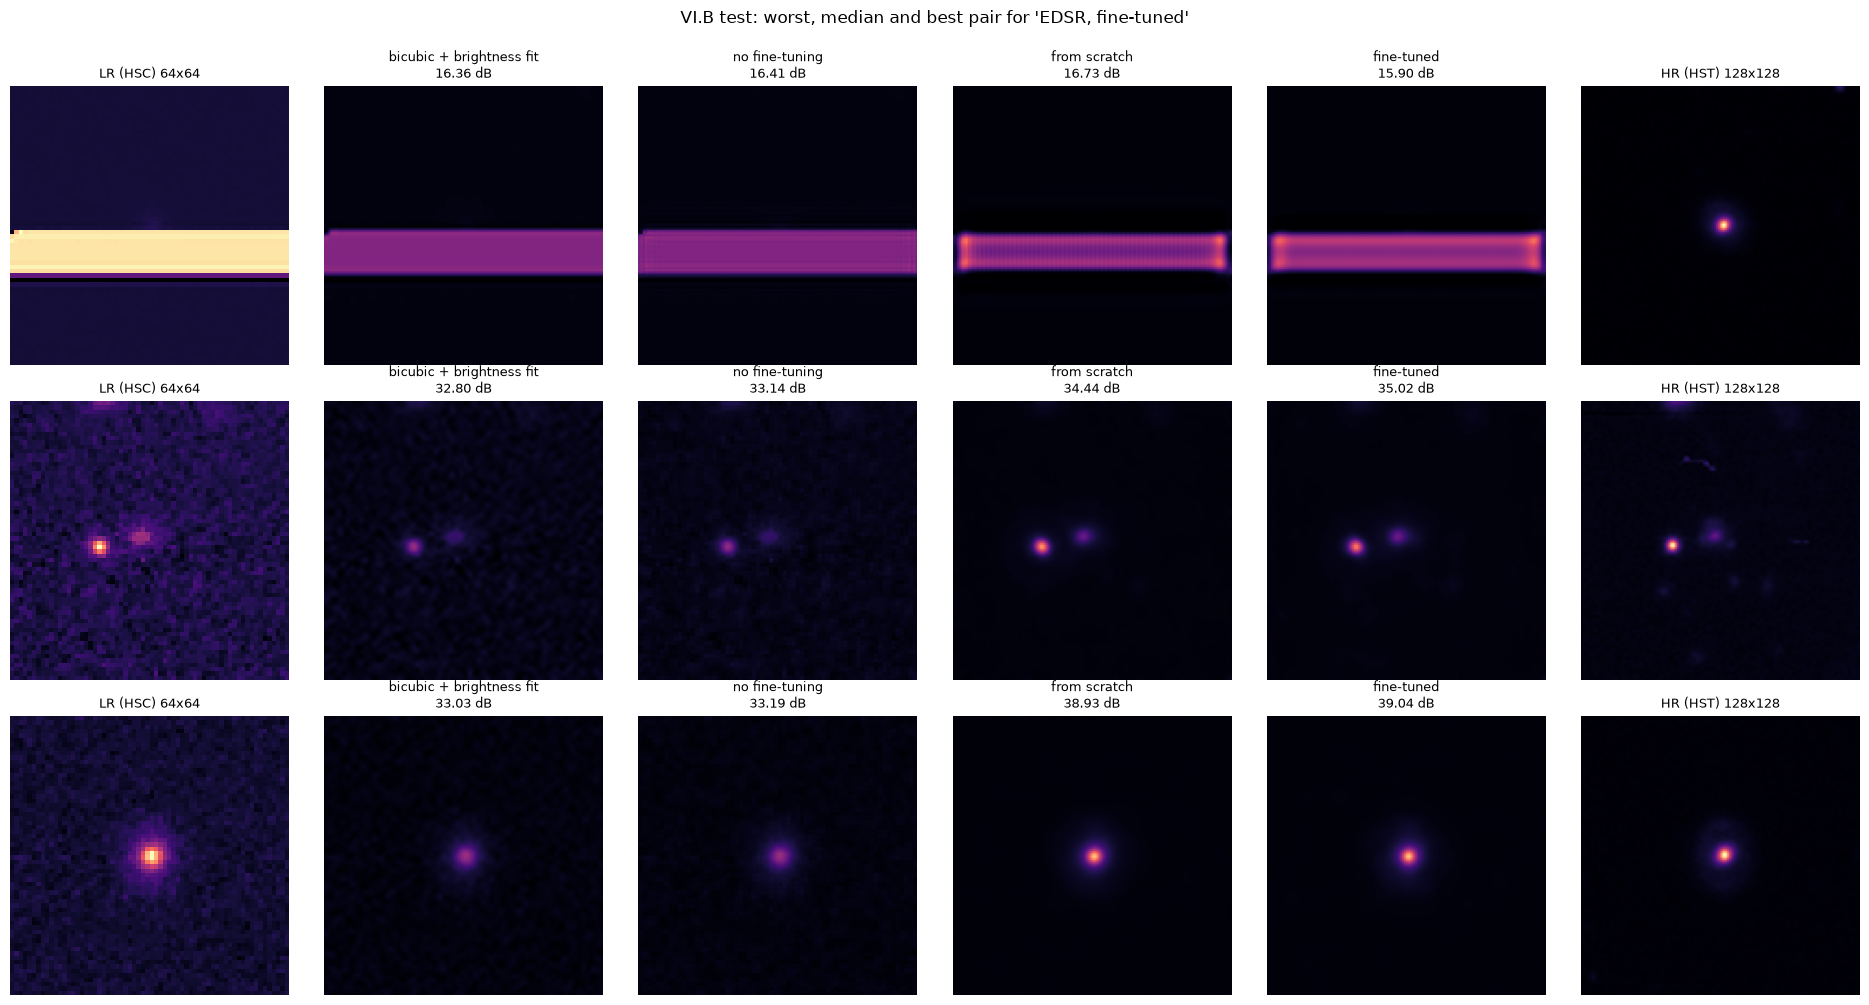

In [8]:
order = ["bicubic + brightness fit", "EDSR, no fine-tuning", "EDSR, from scratch", "EDSR, fine-tuned"]
pick = teb[np.argsort(test_b_img[FINAL_B].psnr.values)[[0, len(teb) // 2, -1]]]
pos = {i: k for k, i in enumerate(teb)}
fig, axes = plt.subplots(3, 6, figsize=(19, 10))
for r, i in enumerate(pick):
    k = pos[i]
    panels = [(LR_B[i], "LR (HSC) 64x64")] + [(SR_B[n][k], f"{n.replace('EDSR, ', '')}\n{test_b_img[n].psnr[k]:.2f} dB") for n in order] \
             + [(HR_B[i], "HR (HST) 128x128")]
    for c, (img, title) in enumerate(panels):
        axes[r, c].imshow(img, cmap="magma", origin="lower", vmin=0, vmax=max(1.0, HR_B[i].max()) if c else None)
        axes[r, c].set_title(title, fontsize=9); axes[r, c].axis("off")
fig.suptitle(f"VI.B test: worst, median and best pair for '{FINAL_B}'", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "05_b_test_examples.png", bbox_inches="tight"); plt.show()

_ = (REPORT / "results_05_superres.json").write_text(json.dumps({
    "vi_a": {"cfg": CFG_A, "best_epoch": best_a["epoch"], "use_tta": bool(USE_TTA),
             "test": test_a.to_dict("index"), "psnr_gain_ci": [float(x) for x in S.bootstrap_diff(m_edsr.psnr, m_bic.psnr)]},
    "vi_b": {"cfg": CFG_B, "use_tta": bool(USE_TTA_B), "final_on_valid": FINAL_B, "valid": sel_b.to_dict("index"),
             "test": test_b.to_dict("index"), "comparisons_test": comparisons}}, indent=2, default=float))

## 5. Notes

**Results (held-out test sets, used once).**

| Data | Method | MSE | PSNR (dB) | SSIM |
|---|---|---|---|---|
| VI.A (n = 1,000) | bicubic | 6.94e-5 | 41.62 | 0.9747 |
| VI.A | **EDSR + 8-view TTA** | **5.81e-5** | **42.39** | **0.9778** |
| VI.B (n = 30) | bicubic | 1.79e-2 | 20.25 | 0.3058 |
| VI.B | bicubic + brightness fit | 2.47e-3 | 29.11 | 0.6704 |
| VI.B | EDSR from VI.A, no fine-tuning | 2.41e-3 | 29.24 | 0.6915 |
| VI.B | EDSR trained from scratch | 2.00e-3 | 32.35 | 0.7975 |
| VI.B | **EDSR fine-tuned from VI.A (chosen on validation)** | 2.13e-3 | **32.41** | **0.7998** |

**What the numbers say.**

* **VI.A.** EDSR beats bicubic by +0.77 dB (95 % CI [+0.76, +0.78]) and is better on every one of the 1,000 test images.
  The gain is small in absolute terms, and almost all of it comes in the first epoch: validation PSNR is 42.25 dB after
  epoch 1 and 42.385 dB after epoch 40, while the training loss stays flat. Notebook 04 showed that the LR images carry
  signal-dependent noise. The remaining error is most likely this noise, which no model can undo, rather than missing
  capacity, so longer training or a bigger network is not expected to help much. Test-time augmentation changed validation
  PSNR by only +0.001 dB.
* **VI.B: the VI.A model alone does not transfer.** Without fine-tuning it is only +0.14 dB better than the brightness-fit
  baseline. Simulated LR images are made by shrinking the HR image; real HSC images come from a different telescope, with
  a different blur, noise level and background. The model has to see real pairs.
* **VI.B: fine-tuning works, and is +3.30 dB (95 % CI [+2.17, +4.42]) better than the brightness-fit baseline**, with SSIM
  rising from 0.67 to 0.80.
* **VI.B: VI.A pre-training does not measurably help the final result.** The fine-tuned and from-scratch models differ by
  +0.06 dB on test (95 % CI [−0.06, +0.17]), which is within noise. The fine-tuned model was chosen because it was better
  on validation (33.38 vs 33.22 dB), but the honest summary is that the two are equal. Pre-training does make learning
  faster: after 10 epochs the fine-tuned model is at 33.0 dB on validation, the from-scratch model at 31.4 dB (learning
  curve figure). With only 243 training pairs this is the main benefit of transfer seen here.
* **Mean MSE and mean PSNR rank the two VI.B models differently** (from scratch has the lower MSE). Mean MSE is dominated by a
  few bad images, while PSNR is averaged on a log scale. The worst test pair (figure above, top row) has a saturated stripe
  across the HSC image, probably a detector artefact, which is not in the Hubble image. Every method scores about 16 dB on it.
  Such pairs are kept in the test set, as decided in notebook 04.

**Limits and next steps.**

* The VI.B test set has only 30 pairs, so differences below about 1 dB cannot be told apart (see the confidence intervals).
  Cross-validation over all 300 pairs would give more reliable numbers.
* The outputs are smoother than real Hubble images: small faint sources in the HST image are not recovered. This is
  expected with an L1 loss, which predicts an average answer when the LR image does not determine the detail.
* PSNR and SSIM do not check whether the lens itself is preserved. Physics-aware checks (total flux, arc shape, the
  classifier from Test I run on super-resolved images) would show whether the output is useful for science.
* Simulating LR images that look like real HSC images (blur, noise, background) for pre-training is the most promising way
  to make transfer from simulation actually help.
* All training ran on the CPU (the shared GPU was busy): about 8 h for VI.A and 33 min per VI.B model.